In [1]:
from visualize import *
from data_generation import *   
from preprocessing import *
from sb import loss
from sb import model
from datasets.dataset import *
from torch.utils.data import DataLoader
import torch.nn.functional as F
import os
from PIL import Image
from scipy.interpolate import griddata
from tqdm import tqdm

In [2]:
high_f_1d = np.load("./data/kf_2d_re1000_256_40seed.npy", mmap_mode="r")
high_f_1d = high_f_1d[:40,:40,:,:]
low_f_1d = np.load("./data/low_fidelity_10%.npy", mmap_mode="r")
low_f_1d = low_f_1d[:40,:40,:,:]
print("GT high PDE (before downsampling) :", loss.phys_loss_kol(torch.tensor(high_f_1d), 1000))
print("GT low PDE (after downsampling) :", loss.phys_loss_kol(torch.tensor(low_f_1d), 1000))

/home/chan/miniconda3/envs/gtg/lib/python3.8/site-packages/torch/functional.py:507: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3549.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


GT high PDE (before downsampling) : tensor(0.7659, grad_fn=<MeanBackward0>)
GT low PDE (after downsampling) : tensor(238.1008, grad_fn=<MeanBackward0>)


In [3]:
mask_high_1d = make_sensor_mask(high_f_1d, n_sensors=256*25, sparse_ratio=None, seed=0)
mask_low_1d = make_sensor_mask(low_f_1d, n_sensors=256*25, sparse_ratio=None, seed=0)
# dataset_visualization(low_f_1d, mask_low_1d, batch_idx=10)
# dataset_visualization(high_f_1d, mask_high_1d, batch_idx=10)

In [4]:
N = low_f_1d.shape[0]
train_ratio = 0.8
val_ratio = 0.1

N_train = int(N * train_ratio)
# N_train = 1
N_val = int(N * val_ratio)
N_test = N - N_train - N_val

low_train  = low_f_1d[:N_train]
high_train = high_f_1d[:N_train]
mask_train = mask_high_1d[:N_train]

low_val  = low_f_1d[N_train:N_train + N_val]
high_val = high_f_1d[N_train:N_train + N_val]
mask_val = mask_high_1d[N_train:N_train + N_val]

low_test  = low_f_1d[N_train + N_val:]
high_test = high_f_1d[N_train + N_val:]
mask_test = mask_high_1d[N_train + N_val:]

ds_train = PDEPairDataset(low_data=low_train, high_data=high_train, mask_low_data=None, mask_high_data=mask_train)
dl_train = DataLoader(ds_train, batch_size=4, shuffle=False, drop_last=False)

ds_val = PDEPairDataset(low_data=low_val, high_data=high_val, mask_low_data=None, mask_high_data=mask_val)
dl_val = DataLoader(ds_val, batch_size=4, shuffle=False, drop_last=False)

ds_test = PDEPairDataset(low_data=low_test, high_data=high_test, mask_low_data=None, mask_high_data=mask_test)
dl_test = DataLoader(ds_test, batch_size=4, shuffle=False, drop_last=False)

In [5]:
sb_object = model.SB_model_ver1(train_dataloader=dl_train, val_dataloader=dl_val, timepoints=[0,1], time_dim=8, steps=10, base_lr=1e-4, save=True, pde_type='kolmo')

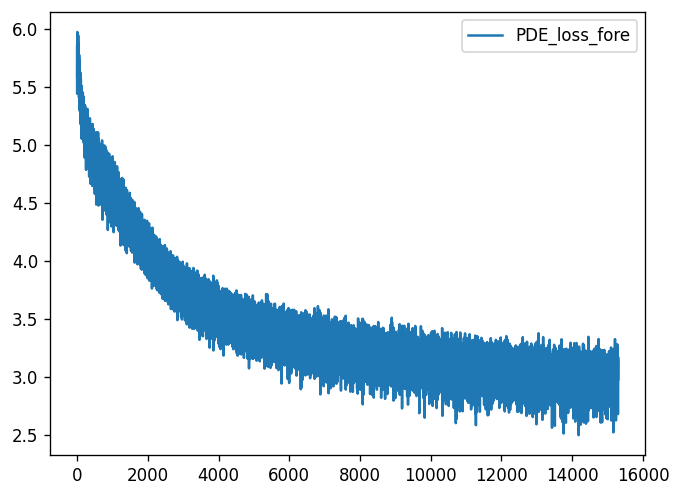

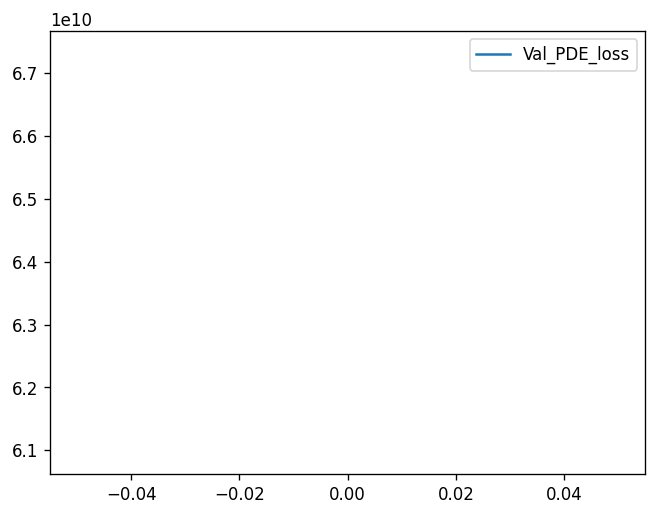

processed: 15354:  16%|█▌        | 15529/100000 [44:15:59<254:58:25, 10.87s/it, MSE_observed=0.64472777, PDE_loss=20.651602, Val_PDE_loss=6.41e+10, Alpha=0.0067153485]

In [ ]:
sb_object.train(train_epochs=100000, model_name='train_test_split_kolmo_10%.pt', known_alpha=1000)

In [ ]:
models_dict=torch.load('./model/train_test_split_kolmo_10%.pt', map_location='cuda')
sb_object.v_fore.load_state_dict(models_dict['v_fore'])
sb_object.time_embed.load_state_dict(models_dict['time_embed'])
sb_object.optimizer_fore.load_state_dict(models_dict['optimizer_fore'])
sb_object.v_fore.train()
sb_object.time_embed.train()
# print(models_dict['alpha'])
# print(models_dict['best_val_pde'])
# loss_history = print(models_dict['loss_history'])       

In [ ]:
sb_object.v_fore.eval()
sb_object.time_embed.eval()

x0_chunks = []
m0_chunks = []
x1_chunks = []
m1_chunks = []
pred_chunks = []
with torch.no_grad():
    for x_0, x_1, mask_low, mask_high in dl_train:
        pred = sb_object.eval_fore(x_0=x_0, x_1=x_1, mask_low=mask_low, mask_high=mask_high)
        x0_chunks.append(x_0.detach().cpu())
        x1_chunks.append(x_1.detach().cpu())
        m0_chunks.append(mask_low.detach().cpu())
        m1_chunks.append(mask_high.detach().cpu())
        pred_chunks.append(pred.detach().cpu())

x0_all = torch.cat(x0_chunks, dim=0)
x1_all = torch.cat(x1_chunks, dim=0)
m0_all = torch.cat(m0_chunks, dim=0)
m1_all = torch.cat(m1_chunks, dim=0)
pred_all = torch.cat(pred_chunks, dim=0)
nwin, C, win_T, X = pred_all.shape
# x0_stitched = x0_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)
# x1_stitched = x1_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)
# m0_stitched = m0_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)
# m1_stitched = m1_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)
# pred_stitched = pred_all.permute(1, 0, 2, 3).contiguous().view(1, 1, nwin * win_T, X)

In [14]:
x0_all.shape


torch.Size([32, 40, 256, 256])

/tmp/ipykernel_336006/3679918420.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dataA=torch.tensor(x0_all)[[0]],
/tmp/ipykernel_336006/3679918420.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  dataB=torch.tensor(x1_all)[[0]],
/home/chan/PISB/PI-BRIDGE/SyukeulimBridge/visualize.py:267: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(u_tx).float(), torch.tensor(coef)


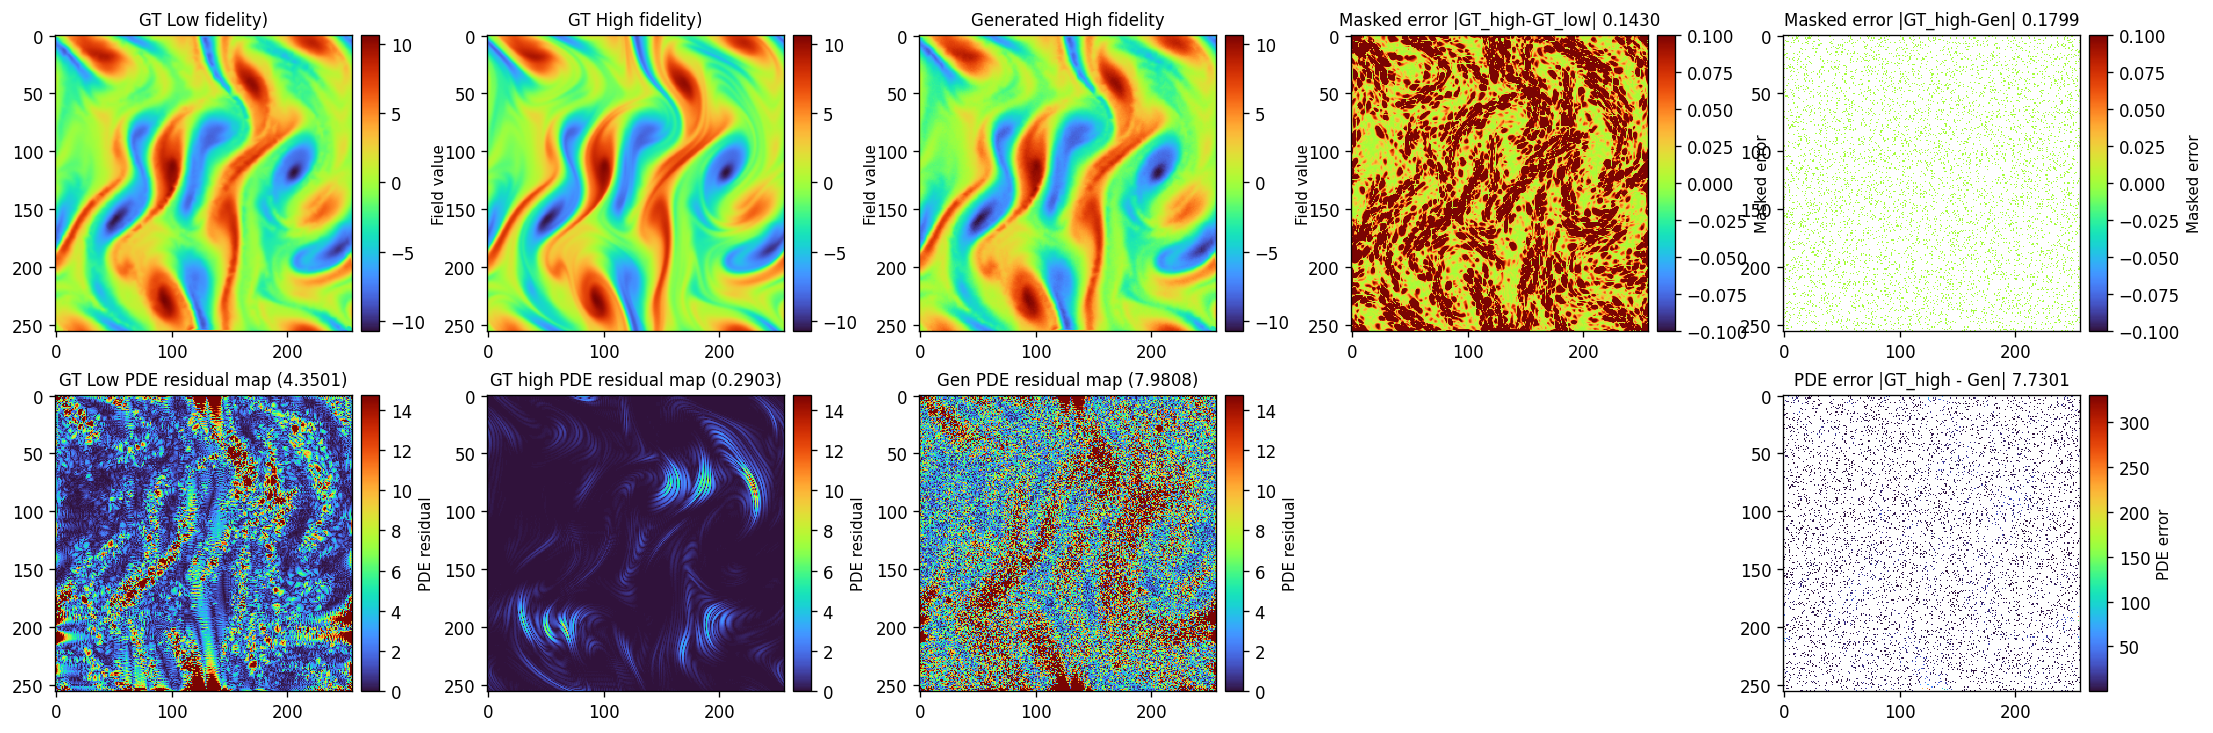

In [15]:
plot_result_3d(
    dataA=torch.tensor(x0_all)[[0]],                  
    dataB=torch.tensor(x1_all)[[0]],                  
    predict=pred_all[[0]],              
    high_resol_coef=1000,
    low_resol_coef=1000,
    snapshot_idx=10,
    mask=m1_all[[0]]           
)